# 05 · Random Forest (handbook 3.5.3)
Exercise 3.5.3.1: keep `n_estimators = 100` and grid search `min_samples_leaf`.
Tuned on a stratified 40k sample, final model on the full training set.

In [1]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

d = load_prepared()
x_train, x_val, x_test = d["x_train"], d["x_val"], d["x_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
feature_names = d["feature_names"]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
from sklearn.ensemble import RandomForestClassifier

train (114844, 1618) | val (28712, 1618) | test (35890, 1618)


## Grid search over min_samples_leaf

In [2]:
xs, ys = stratified_sample(x_train, y_train, 40000)
N = [1, 2, 5, 10, 20]
f1_val = []
for n in N:
    m = RandomForestClassifier(n_estimators=100, min_samples_leaf=n, random_state=0, n_jobs=-1).fit(xs, ys)
    f1_val.append(macro_f1(y_val, m.predict(x_val)))
    print(n, round(f1_val[-1], 4))
leaf_opt = N[int(np.argmax(f1_val))]
print("Optimal min_samples_leaf:", leaf_opt)

1 0.5438
2 0.5312
5 0.494
10 0.4609
20 0.4373
Optimal min_samples_leaf: 1


## Final model: evaluate on test and save

{'model': 'Random Forest', 'accuracy': 0.5929, 'macro_F1': 0.5806, 'ordinal_MAE': 0.6106, 'within_one': 0.8597, 'EFG_recall': 0.7831, 'AUC_ovr': 0.912}


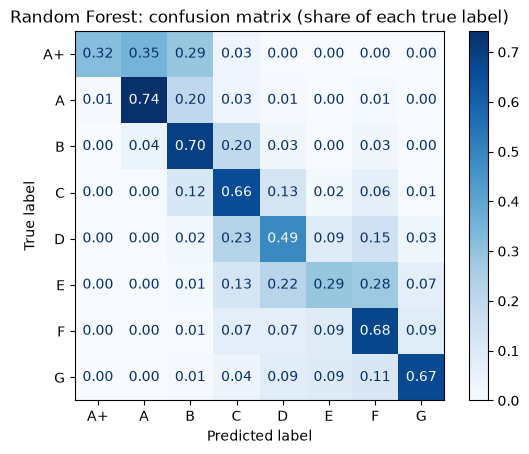

In [3]:
RF = RandomForestClassifier(n_estimators=100, min_samples_leaf=leaf_opt, random_state=0, n_jobs=-1).fit(x_train, y_train)
evaluate("Random Forest", RF, x_test, y_test)
save_model(RF, "RF")

## Feature importance

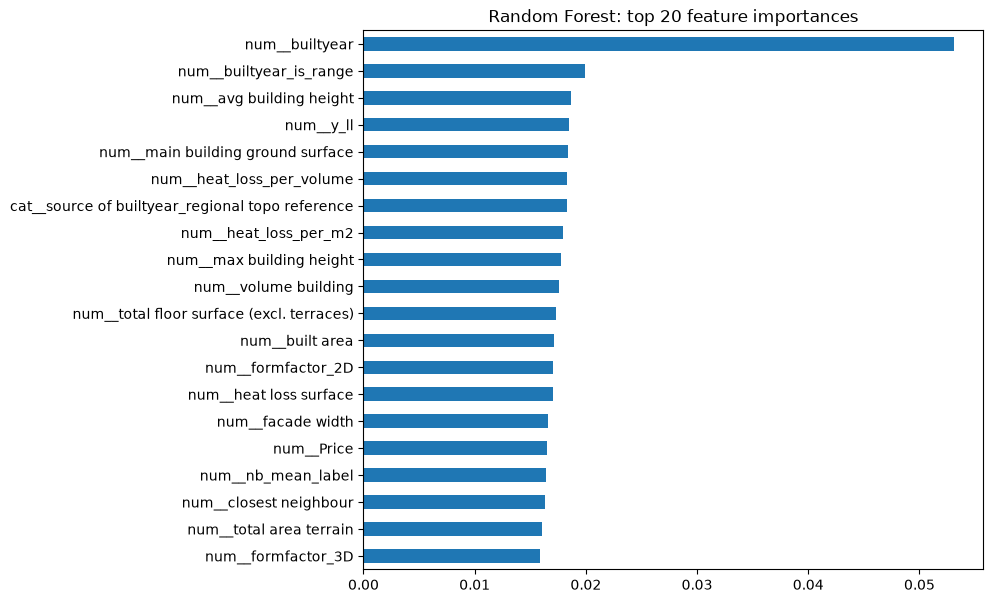

In [4]:
pd.Series(RF.feature_importances_, index=feature_names).sort_values().tail(20).plot(kind="barh", figsize=(8, 7))
plt.title("Random Forest: top 20 feature importances")
plt.show()